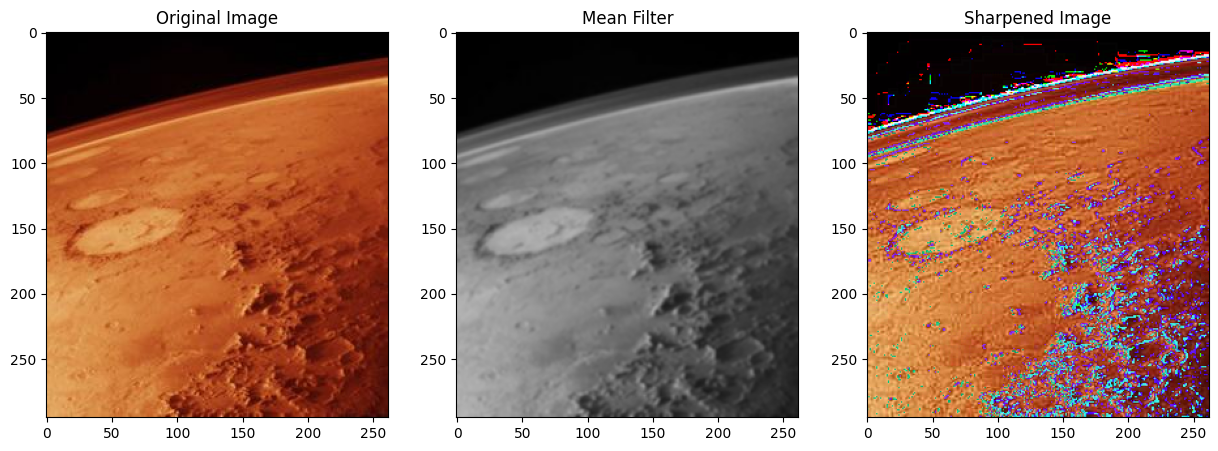

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def mean(image, k):
    img_filtered = np.zeros_like(image, dtype=np.uint8)
    pad = k // 2
    padded_img = cv2.copyMakeBorder(image, pad, pad, pad, pad, cv2.BORDER_REFLECT)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            neighborhood = padded_img[i:i+k, j:j+k]
            img_filtered[i, j] = np.mean(neighborhood)

    return img_filtered

def sharpening(image, k, w):
    img_filtered = mean(image, 5)
    new_img = image - img_filtered
    sharpened = image + 3 * new_img
    return np.clip(sharpened, 0, 255).astype(np.uint8)

img = cv2.imread('/content/Mars.JPG')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
filtered_gray = mean(gray, 3)

sharpened_bgr = np.zeros_like(img, dtype=np.uint8)
for i in range(3):
    sharpened_bgr[:, :, i] = sharpening(img[:, :, i], 3, 1)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
ax[0].set_title("Original Image")

ax[1].imshow(cv2.cvtColor(filtered_gray, cv2.COLOR_GRAY2RGB))
ax[1].set_title("Mean Filter")

ax[2].imshow(cv2.cvtColor(sharpened_bgr, cv2.COLOR_BGR2RGB))
ax[2].set_title("Sharpened Image")

plt.show()


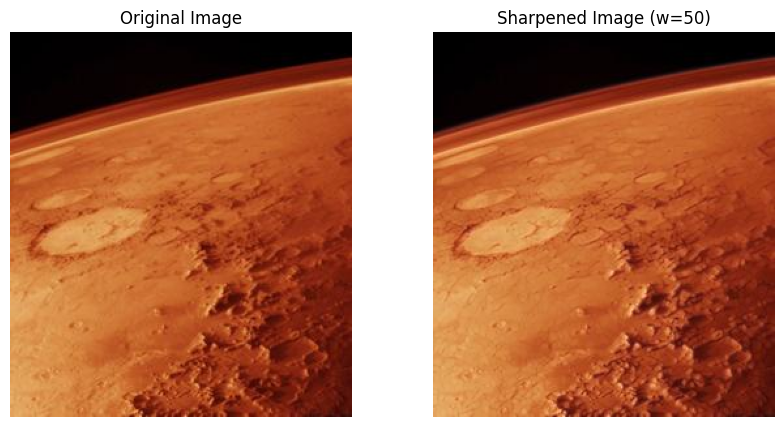

In [36]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def sharpen_image(image_path, w):

    img = cv2.imread('/content/Mars.JPG')
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=5)
    sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=5)
    M = np.sqrt(sobelx**2 + sobely**2)
    M = np.uint8(255 * M / np.max(M))
    M_rgb = cv2.cvtColor(M, cv2.COLOR_GRAY2RGB)
    S = img_rgb.astype(np.float32) + (w * M_rgb.astype(np.float32) / 255)
    S = np.clip(S, 0, 255).astype(np.uint8)
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img_rgb)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(S)
    plt.title(f"Sharpened Image (w={w})")
    plt.axis("off")
    plt.show()

sharpen_image(img, w=50)
